# Statistical Hypothesis Testing — AI4I Predictive Maintenance Analytics

I test whether selected operating conditions are associated with failure outcomes, using the observed development data at their existing class balance.

**Inputs**
- `data/cleaned/ai4i2020_cleaned.csv`
- `reports/smote/split_manifest.csv`
- `reports/smote/experiment_settings.json`

**Outputs created during this run**
- Tables and settings in `reports/hypothesis_testing/`
- Charts in `visuals/hypothesis_testing/`

I exclude the final-test observations recorded in the split manifest. I use no oversampling, class weighting, or synthetic observations for these statistical tests.


## 1. Specify the hypotheses

| Hypothesis | Null hypothesis | Alternative hypothesis | Planned analysis |
|---|---|---|---|
| H1: thermal and load interaction | The temperature-difference × torque coefficient is zero in the specified logistic model for HDF | The interaction coefficient differs from zero | Binomial logistic regression with a two-sided robust Wald test |
| H2: sensor mean differences | For each sensor, failed and non-failed observations have the same population mean | The two means differ | Five two-sided Welch ANOVA tests |
| H3: ensemble performance | The specified ensemble does not improve average precision over its specified comparators | It improves average precision | Pending the model-comparison stage |

For H1, the outcome is **HDF**, the heat-dissipation-failure indicator. For H2, the outcome grouping is the overall **Machine failure** label. I keep these outcomes distinct.

I set **alpha = 0.05** and apply the Holm correction to the six primary p-values: one H1 interaction test and five H2 sensor tests. I calculate decisions from the results, rather than assuming every hypothesis will be supported.

These hypotheses follow exploratory analysis on this synthetic dataset, so I interpret the tests as exploratory, model-dependent evidence. Statistical significance alone does not establish causation, practical importance, or performance on real machinery.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import stats
import scipy
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway

ALPHA = 0.05
SENSOR_COLUMNS = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
PRIMARY_TERM = "temp_z:torque_z"
plt.rcParams["figure.figsize"] = (9, 5)

print(f"Python: {platform.python_version()}")
print(f"SciPy: {scipy.__version__}; statsmodels: {statsmodels.__version__}")


Python: 3.13.5
SciPy: 1.15.3; statsmodels: 0.14.4


## 2. Load data and verify the saved split

I match the cleaned CSV to the experiment settings using its checksum, then validate the split manifest against UDI and the supplied target labels. This prevents silently using a different dataset or assigning observations to a new split.

I combine the training and validation observations into the development sample for the association tests. I leave the final-test observations out of the fitted models and sensor comparisons.


In [2]:
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "cleaned" / "ai4i2020_cleaned.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/cleaned/ai4i2020_cleaned.csv. Run the cleaning notebook first."
    )

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "ai4i2020_cleaned.csv"
MANIFEST_PATH = PROJECT_ROOT / "reports" / "smote" / "split_manifest.csv"
SMOTE_SETTINGS_PATH = PROJECT_ROOT / "reports" / "smote" / "experiment_settings.json"

for path in [MANIFEST_PATH, SMOTE_SETTINGS_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.name}. Run 03b_smote_experiment.ipynb first.")

input_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
manifest_sha256 = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
smote_settings = json.loads(SMOTE_SETTINGS_PATH.read_text(encoding="utf-8"))
if smote_settings["input_sha256"] != input_sha256:
    raise ValueError("The cleaned CSV differs from the dataset recorded by the SMOTE experiment.")

df = pd.read_csv(DATA_PATH)
manifest = pd.read_csv(MANIFEST_PATH)
required = ["UDI", "Machine failure", "HDF", *SENSOR_COLUMNS]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing data columns: {missing}")
if not {"UDI", "Machine failure", "split"}.issubset(manifest.columns):
    raise ValueError("The split manifest is missing required columns.")
if df[required].isna().any().any() or manifest.isna().any().any():
    raise ValueError("Required data and split fields must not contain missing values.")
if df["UDI"].duplicated().any() or manifest["UDI"].duplicated().any():
    raise ValueError("UDI must be unique in the dataset and split manifest.")
if set(df["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The split manifest must cover exactly the cleaned dataset.")
if not set(manifest["split"]).issubset({"train", "validation", "final_test"}):
    raise ValueError("Unexpected split names in the manifest.")
if not {"train", "validation", "final_test"}.issubset(set(manifest["split"])):
    raise ValueError("The manifest must include train, validation, and final_test observations.")

joined = df.merge(
    manifest.rename(columns={"Machine failure": "manifest_target"}),
    on="UDI", how="left", validate="one_to_one",
)
if not joined["Machine failure"].eq(joined["manifest_target"]).all():
    raise ValueError("Target labels differ between the cleaned CSV and the manifest.")

analysis = joined.loc[joined["split"].isin(["train", "validation"])].copy()
excluded_test_udi = set(joined.loc[joined["split"].eq("final_test"), "UDI"])
assert set(analysis["UDI"]).isdisjoint(excluded_test_udi)

for target in ["Machine failure", "HDF"]:
    if not analysis[target].isin([0, 1]).all() or analysis[target].nunique() != 2:
        raise ValueError(f"{target} must contain both binary outcome classes.")
if not np.isfinite(analysis[SENSOR_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError("Sensor readings must be numeric and finite.")

REPORTS_DIR = PROJECT_ROOT / "reports" / "hypothesis_testing"
VISUALS_DIR = PROJECT_ROOT / "visuals" / "hypothesis_testing"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

analysis["temp_diff"] = (
    analysis["Process temperature [K]"] - analysis["Air temperature [K]"]
)
print(f"Development observations included: {len(analysis):,}")
print(f"Final-test observations excluded: {len(excluded_test_udi):,}")
print(f"Development machine failures: {int(analysis['Machine failure'].sum()):,}")
print(f"Development HDF events: {int(analysis['HDF'].sum()):,}")
display(analysis.groupby("Machine failure")[SENSOR_COLUMNS].agg(["count", "mean", "std"]).round(3))


Development observations included: 8,000
Final-test observations excluded: 2,000
Development machine failures: 271
Development HDF events: 86


Air temperature [K]           ... Tool wear [min]        
                              count     mean  ...            mean     std
Machine failure                               ...                        
0                              7729  299.973  ...         106.503  62.860
1                               271  300.923  ...         141.387  74.854

[2 rows x 15 columns]

## 3. H1 — Temperature difference and torque interaction

I define temperature difference as process temperature minus air temperature. I standardize temperature difference and torque within the development sample, then fit:

`logit(P(HDF = 1)) = intercept + beta1 × temp_z + beta2 × torque_z + beta3 × temp_z × torque_z`

The primary H1 test concerns **beta3**, not whether any coefficient in the model is significant. I use a binomial GLM with HC0 sandwich standard errors and retain the observed class frequencies.

This model examines a specified association. It does not isolate a causal heat mechanism or adjust for every operating variable. The tests treat rows as independent; robust standard errors do not resolve unmeasured row dependence or model misspecification.

Reference: [statsmodels GLM documentation](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html).


In [3]:
temperature_mean = float(analysis["temp_diff"].mean())
temperature_sd = float(analysis["temp_diff"].std(ddof=0))
torque_mean = float(analysis["Torque [Nm]"].mean())
torque_sd = float(analysis["Torque [Nm]"].std(ddof=0))
if min(temperature_sd, torque_sd) <= 0:
    raise ValueError("H1 predictors must vary.")

h1_data = pd.DataFrame({
    "hdf": analysis["HDF"].astype(int),
    "temp_z": (analysis["temp_diff"] - temperature_mean) / temperature_sd,
    "torque_z": (analysis["Torque [Nm]"] - torque_mean) / torque_sd,
}, index=analysis.index)

# A convergence or separation problem should be investigated before interpreting p-values.
with warnings.catch_warnings(record=True) as h1_fit_warnings:
    warnings.simplefilter("always")
    h1_model = smf.glm(
        "hdf ~ temp_z * torque_z",
        data=h1_data,
        family=sm.families.Binomial(),
    ).fit(cov_type="HC0", maxiter=200)

warning_messages = [str(item.message) for item in h1_fit_warnings]
if any("separation" in message.lower() for message in warning_messages):
    raise RuntimeError("Separation detected in H1. Investigate the model before interpreting it.")
if not h1_model.converged:
    raise RuntimeError("H1 did not converge.")
if not np.isfinite(h1_model.params.to_numpy()).all() or not np.isfinite(h1_model.pvalues.to_numpy()).all():
    raise RuntimeError("H1 has nonfinite estimates or p-values.")

confidence_intervals = h1_model.conf_int(alpha=ALPHA)
h1_coefficients = pd.DataFrame({
    "coefficient": h1_model.params,
    "robust_standard_error": h1_model.bse,
    "wald_z": h1_model.tvalues,
    "raw_p_value": h1_model.pvalues,
    "coefficient_CI_low": confidence_intervals[0],
    "coefficient_CI_high": confidence_intervals[1],
    "odds_multiplier": np.exp(h1_model.params),
    "odds_multiplier_CI_low": np.exp(confidence_intervals[0]),
    "odds_multiplier_CI_high": np.exp(confidence_intervals[1]),
})
display(h1_coefficients)
h1_raw_p = float(h1_model.pvalues[PRIMARY_TERM])

print(f"Interaction raw p-value: {h1_raw_p:.6g}")
print("The final H1 decision is calculated after correcting the six primary p-values.")
print("Nuisance-coefficient p-values above are descriptive; only the interaction is the H1 primary test.")
if warning_messages:
    print("Fit warnings:", warning_messages)


Interaction raw p-value: 2.81429e-06
The final H1 decision is calculated after correcting the six primary p-values.
Nuisance-coefficient p-values above are descriptive; only the interaction is the H1 primary test.


,coefficient,robust_standard_error,wald_z,raw_p_value,coefficient_CI_low,coefficient_CI_high,odds_multiplier,odds_multiplier_CI_low,odds_multiplier_CI_high
Intercept,-8.345927,0.255986,-32.603000,3.718710e-233,-8.847651,-7.844202,0.000237,0.000144,0.000392
temp_z,-2.627682,0.156610,-16.778512,3.505082e-63,-2.934632,-2.320732,0.072246,0.053150,0.098202
torque_z,0.074557,0.278851,0.267372,7.891828e-01,-0.471981,0.621095,1.077407,0.623765,1.860965
temp_z:torque_z,-1.242149,0.265194,-4.683928,2.814294e-06,-1.761920,-0.722379,0.288763,0.171715,0.485596


## 4. Visualize the H1 association

I show the observed temperature–torque combinations alongside fitted HDF probabilities at the 25th and 75th percentiles of development torque.

The interaction coefficient describes how the temperature slope on the **log-odds** scale changes with standardized torque. Its exponent is an interaction multiplier, not a standalone increase in failure odds for either sensor. Visual separation of curves alone is not a significance test.

The curves are descriptive fitted values, not validated risk forecasts, and can include sensor combinations with limited observed support.


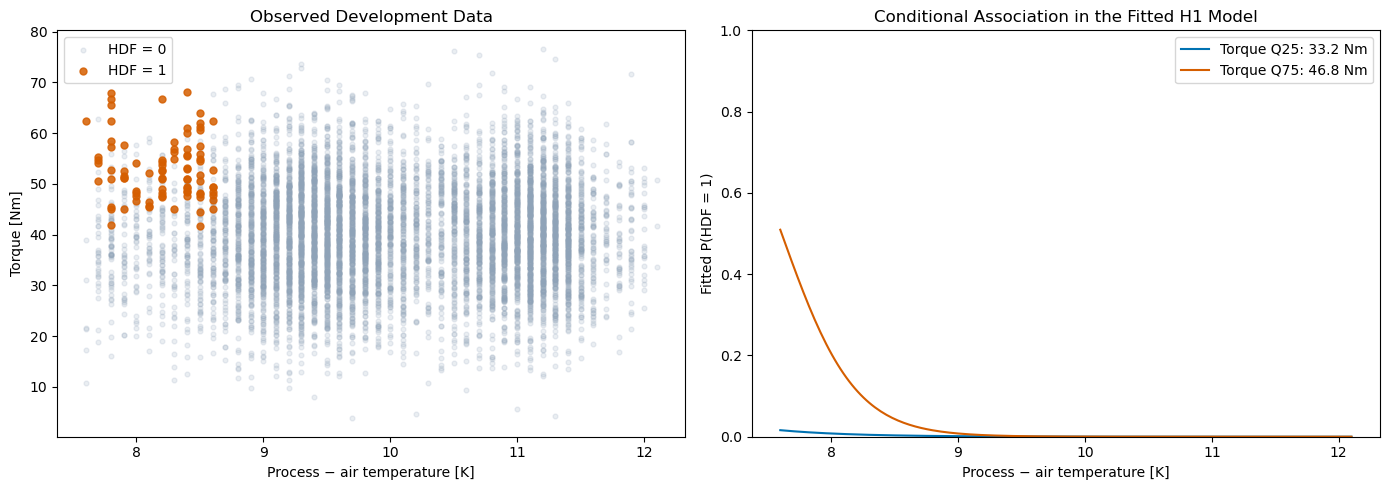

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for event, color, label in [
    (0, "#8FA3B8", "HDF = 0"),
    (1, "#D55E00", "HDF = 1"),
]:
    subset = analysis.loc[analysis["HDF"].eq(event)]
    axes[0].scatter(
        subset["temp_diff"], subset["Torque [Nm]"],
        s=12 if event == 0 else 25,
        alpha=0.18 if event == 0 else 0.85,
        color=color, label=label,
    )
axes[0].set_xlabel("Process − air temperature [K]")
axes[0].set_ylabel("Torque [Nm]")
axes[0].set_title("Observed Development Data")
axes[0].legend()

temperature_grid = np.linspace(analysis["temp_diff"].min(), analysis["temp_diff"].max(), 200)
h1_curve_frames = []
for quantile, color in [(0.25, "#0072B2"), (0.75, "#D55E00")]:
    torque_value = float(analysis["Torque [Nm]"].quantile(quantile))
    prediction_frame = pd.DataFrame({
        "temp_z": (temperature_grid - temperature_mean) / temperature_sd,
        "torque_z": (torque_value - torque_mean) / torque_sd,
    })
    probability = h1_model.predict(prediction_frame).to_numpy()
    axes[1].plot(
        temperature_grid, probability, color=color,
        label=f"Torque Q{int(quantile * 100)}: {torque_value:.1f} Nm",
    )
    h1_curve_frames.append(pd.DataFrame({
        "temperature_difference_K": temperature_grid,
        "torque_Nm": torque_value,
        "fitted_HDF_probability": probability,
    }))
axes[1].set_xlabel("Process − air temperature [K]")
axes[1].set_ylabel("Fitted P(HDF = 1)")
axes[1].set_ylim(0, 1)
axes[1].set_title("Conditional Association in the Fitted H1 Model")
axes[1].legend()
plt.tight_layout()
plt.savefig(VISUALS_DIR / "h1_temperature_torque_interaction.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

h1_curve_data = pd.concat(h1_curve_frames, ignore_index=True)


## 5. H2 — Sensor mean differences by machine-failure status

For each of the five sensor variables, I compare failed and non-failed observations using Welch ANOVA. With two groups this tests the same mean-equality null as a two-sided Welch t-test.

I use Welch's method consistently because equal variances are not required. I also report the median-centered Levene test as a variance diagnostic; it does not determine which primary test I select.

I report the mean difference as **failure minus no failure**, with a separate, unadjusted 95% Welch confidence interval in the sensor's units. The Holm-adjusted p-values determine decisions; the individual confidence intervals are not simultaneous family-wise intervals.

Reference: [Welch ANOVA documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway.anova_oneway.html).


In [5]:
not_failed = analysis.loc[analysis["Machine failure"].eq(0)]
failed = analysis.loc[analysis["Machine failure"].eq(1)]
if min(len(not_failed), len(failed)) < 2:
    raise ValueError("Welch tests require at least two observations in each group.")

h2_rows = []
for sensor in SENSOR_COLUMNS:
    group0 = not_failed[sensor].to_numpy(dtype=float)
    group1 = failed[sensor].to_numpy(dtype=float)
    n0, n1 = len(group0), len(group1)
    mean0, mean1 = group0.mean(), group1.mean()
    var0, var1 = group0.var(ddof=1), group1.var(ddof=1)

    welch = anova_oneway([group0, group1], use_var="unequal")
    levene = stats.levene(group0, group1, center="median")
    variance0, variance1 = var0 / n0, var1 / n1
    standard_error = np.sqrt(variance0 + variance1)
    if standard_error <= 0:
        raise ValueError(f"No usable variation for the Welch comparison of {sensor}.")
    welch_df = (variance0 + variance1) ** 2 / (
        variance0 ** 2 / (n0 - 1) + variance1 ** 2 / (n1 - 1)
    )
    critical_t = stats.t.ppf(1 - ALPHA / 2, df=welch_df)
    difference = mean1 - mean0

    h2_rows.append({
        "sensor": sensor,
        "n_no_failure": n0,
        "n_failure": n1,
        "mean_no_failure": float(mean0),
        "mean_failure": float(mean1),
        "mean_difference_failure_minus_no_failure": float(difference),
        "mean_difference_CI_low": float(difference - critical_t * standard_error),
        "mean_difference_CI_high": float(difference + critical_t * standard_error),
        "welch_F": float(welch.statistic),
        "welch_df_numerator": float(welch.df[0]),
        "welch_df_denominator": float(welch.df[1]),
        "raw_p_value": float(welch.pvalue),
        "levene_median_p_diagnostic": float(levene.pvalue),
    })

h2_results = pd.DataFrame(h2_rows).set_index("sensor")
display(h2_results)


,n_no_failure,n_failure,mean_no_failure,mean_failure,mean_difference_failure_minus_no_failure,mean_difference_CI_low,mean_difference_CI_high,welch_F,welch_df_numerator,welch_df_denominator,raw_p_value,levene_median_p_diagnostic
sensor,,,,,,,,,,,,
Air temperature [K],7729,271,299.973295,300.922509,0.949214,0.699740,1.198688,56.082915,1.0,288.020098,8.538220e-13,5.626569e-01
Process temperature [K],7729,271,309.994747,310.328782,0.334035,0.167661,0.500410,15.613701,1.0,292.811817,9.743316e-05,6.880504e-04
Rotational speed [rpm],7729,271,1540.711217,1500.730627,-39.980590,-86.742390,6.781210,2.833109,1.0,273.569061,9.348022e-02,2.180104e-13
Torque [Nm],7729,271,39.646850,50.171218,10.524368,8.531050,12.517687,108.030937,1.0,276.277416,1.420699e-21,6.688652e-30
Tool wear [min],7729,271,106.503299,141.387454,34.884155,25.823890,43.944420,57.436321,1.0,283.511423,4.985775e-13,5.050038e-08


## 6. Correct the six primary p-values and calculate decisions

I use Holm's method to control the family-wise error rate for this set of six primary tests. It does not require the test statistics to be independent.

I reject a null hypothesis only when its adjusted p-value is below 0.05. Otherwise I report **fail to reject H0**; this does not establish that the null is true.

Reference: [multiple-testing correction documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).


In [6]:
primary_tests = pd.DataFrame([
    {
        "hypothesis": "H1",
        "comparison": "Temperature difference × torque interaction",
        "outcome": "HDF",
        "test": "Binomial GLM, HC0 robust two-sided Wald test",
        "raw_p_value": h1_raw_p,
    },
    *[
        {
            "hypothesis": "H2",
            "comparison": sensor,
            "outcome": "Machine failure groups",
            "test": "Welch ANOVA",
            "raw_p_value": float(h2_results.loc[sensor, "raw_p_value"]),
        }
        for sensor in SENSOR_COLUMNS
    ],
])

reject, adjusted_p, _, _ = multipletests(
    primary_tests["raw_p_value"].to_numpy(),
    alpha=ALPHA, method="holm",
)
primary_tests["adjusted_p_value"] = adjusted_p
primary_tests["reject_H0"] = reject
primary_tests["decision"] = np.where(reject, "Reject H0", "Fail to reject H0")
display(primary_tests)

h2_results["adjusted_p_value"] = primary_tests.loc[
    primary_tests["hypothesis"].eq("H2"), "adjusted_p_value"
].to_numpy()
h2_results["reject_H0"] = primary_tests.loc[
    primary_tests["hypothesis"].eq("H2"), "reject_H0"
].to_numpy()

h1_decision = primary_tests.iloc[0]
print(f"H1: {h1_decision['decision']} (Holm-adjusted p = {h1_decision['adjusted_p_value']:.6g})")
print(f"Interaction coefficient: {h1_model.params[PRIMARY_TERM]:.4f}")
print(
    "As torque increases, the fitted temperature-difference slope on the log-odds scale "
    + ("decreases." if h1_model.params[PRIMARY_TERM] < 0 else "increases.")
)
significant_sensors = h2_results.index[h2_results["reject_H0"]].tolist()
print(f"\nH2: {len(significant_sensors)} of {len(SENSOR_COLUMNS)} sensor comparisons reject H0.")
print("Sensors with evidence of mean differences after correction:", significant_sensors)
print("These tests assess mean differences; they do not rank predictive feature importance.")


H1: Reject H0 (Holm-adjusted p = 8.44288e-06)
Interaction coefficient: -1.2421
As torque increases, the fitted temperature-difference slope on the log-odds scale decreases.

H2: 4 of 5 sensor comparisons reject H0.
Sensors with evidence of mean differences after correction: ['Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']
These tests assess mean differences; they do not rank predictive feature importance.


,hypothesis,comparison,outcome,test,raw_p_value,adjusted_p_value,reject_H0,decision
0,H1,Temperature difference × torque interaction,HDF,"Binomial GLM, HC0 robust two-sided Wald test",2.814294e-06,8.442882e-06,True,Reject H0
1,H2,Air temperature [K],Machine failure groups,Welch ANOVA,8.538220e-13,3.415288e-12,True,Reject H0
2,H2,Process temperature [K],Machine failure groups,Welch ANOVA,9.743316e-05,1.948663e-04,True,Reject H0
3,H2,Rotational speed [rpm],Machine failure groups,Welch ANOVA,9.348022e-02,9.348022e-02,False,Fail to reject H0
4,H2,Torque [Nm],Machine failure groups,Welch ANOVA,1.420699e-21,8.524193e-21,True,Reject H0
5,H2,Tool wear [min],Machine failure groups,Welch ANOVA,4.985775e-13,2.492888e-12,True,Reject H0


## 7. Visualize sensor readings by failure status

I compare the distributions behind the H2 tests. The boxplots hide individual points outside the whiskers for readability, but every development observation remains included in the statistical calculations.


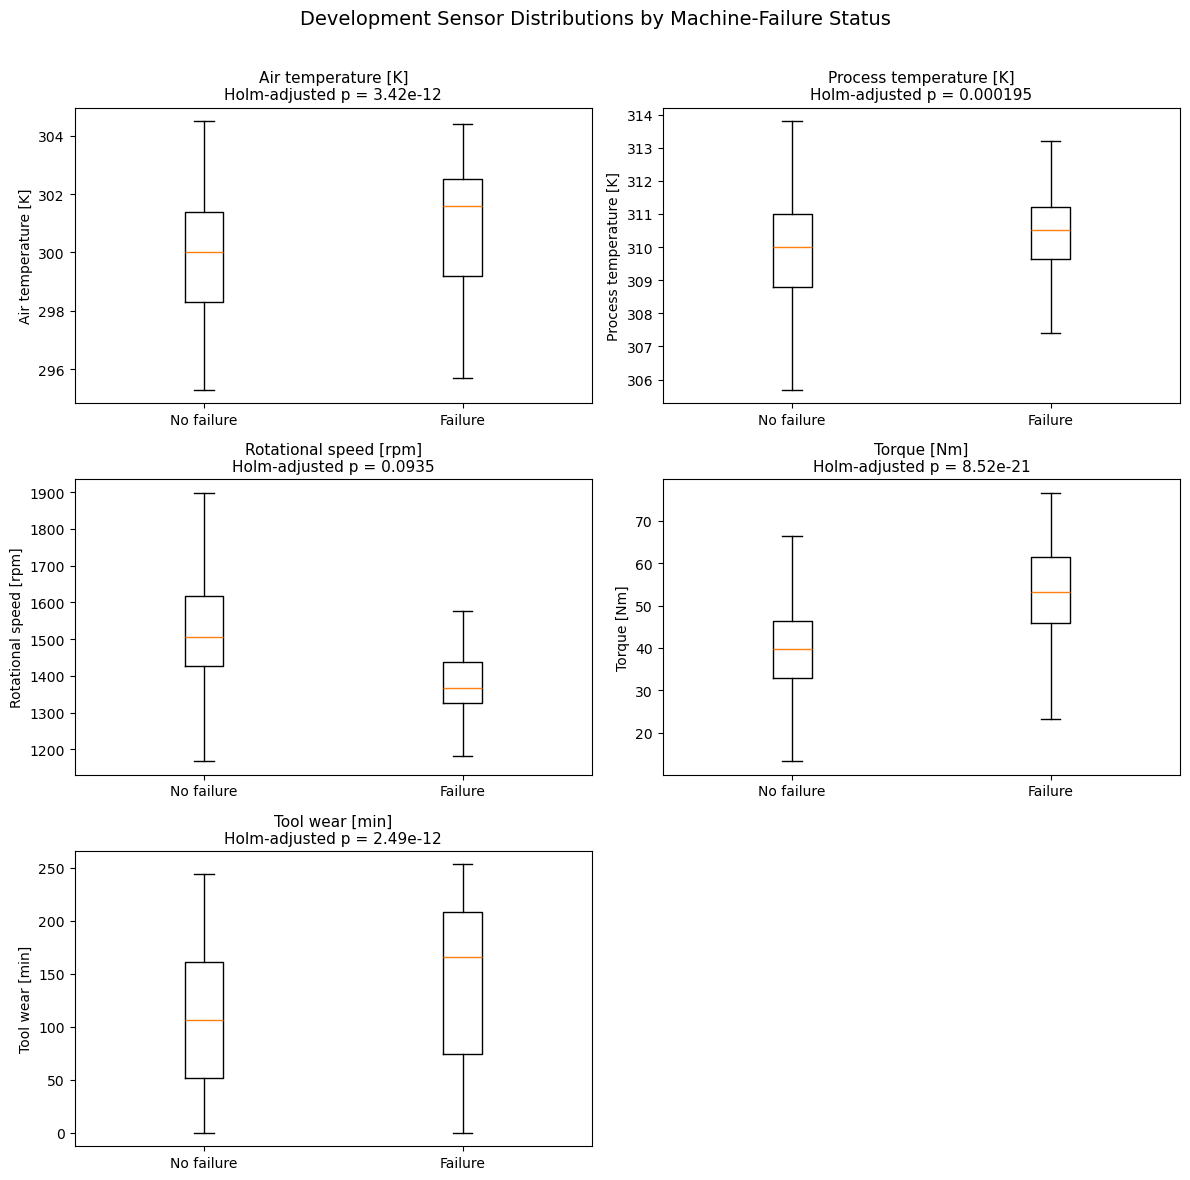

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, sensor in zip(axes.ravel(), SENSOR_COLUMNS):
    ax.boxplot(
        [not_failed[sensor].to_numpy(), failed[sensor].to_numpy()],
        showfliers=False,
    )
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No failure", "Failure"])
    ax.set_ylabel(sensor)
    p_adjusted = h2_results.loc[sensor, "adjusted_p_value"]
    ax.set_title(f"{sensor}\nHolm-adjusted p = {p_adjusted:.3g}", fontsize=11)
axes.ravel()[-1].set_visible(False)
fig.suptitle("Development Sensor Distributions by Machine-Failure Status", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(VISUALS_DIR / "h2_sensor_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 8. H3 — Ensemble-performance hypothesis

I have not yet trained and compared the ensemble models, so I record **H3 as pending**. The SMOTE experiment compares imbalance strategies for Random Forest; it does not evaluate the proposed multi-model ensembles.

At the model-comparison stage, I will specify the ensemble, comparators, and primary performance metric before evaluating frozen models. Paired predictions on the same untouched evaluation observations will be needed for a suitable uncertainty analysis.

I do not use precision, recall, F1, ROC-AUC, and average precision as independent repeats in a Friedman test. They measure different quantities. Likewise, cross-validation folds from one dataset share training observations and should not be treated as independent datasets.

I make no ensemble-superiority claim in this notebook.


In [8]:
h3_status = {
    "hypothesis": "H3",
    "comparison": "Specified ensemble versus specified baseline models",
    "outcome": "Average precision on untouched evaluation observations",
    "test": "Pending model training and a prespecified paired comparison",
    "raw_p_value": None,
    "adjusted_p_value": None,
    "reject_H0": None,
    "decision": "Pending — ensemble models not yet evaluated",
}
hypothesis_summary = pd.concat([
    primary_tests,
    pd.DataFrame([h3_status]),
], ignore_index=True)
display(hypothesis_summary[[
    "hypothesis", "comparison", "adjusted_p_value", "decision"
]])


<ipython-input-8-fd18d6e551bd>:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  hypothesis_summary = pd.concat([


,hypothesis,comparison,adjusted_p_value,decision
0,H1,Temperature difference × torque interaction,8.442882e-06,Reject H0
1,H2,Air temperature [K],3.415288e-12,Reject H0
2,H2,Process temperature [K],1.948663e-04,Reject H0
3,H2,Rotational speed [rpm],9.348022e-02,Fail to reject H0
4,H2,Torque [Nm],8.524193e-21,Reject H0
5,H2,Tool wear [min],2.492888e-12,Reject H0
6,H3,Specified ensemble versus specified baseline m...,NaN,Pending — ensemble models not yet evaluated


## 9. Save the results and analysis settings

I save the test results, fitted coefficient table, descriptive curves, analysis-observation manifest, and settings. I also verify that the input CSV and split manifest remain unchanged.


In [9]:
primary_tests.to_csv(REPORTS_DIR / "primary_hypothesis_tests.csv", index=False)
hypothesis_summary.to_csv(REPORTS_DIR / "hypothesis_summary.csv", index=False)
h1_coefficients.to_csv(REPORTS_DIR / "h1_logistic_coefficients.csv")
h1_curve_data.to_csv(REPORTS_DIR / "h1_fitted_curves.csv", index=False)
h2_results.to_csv(REPORTS_DIR / "h2_sensor_mean_tests.csv")
analysis[["UDI", "split", "Machine failure", "HDF"]].to_csv(
    REPORTS_DIR / "analysis_observations.csv", index=False,
)

settings = {
    "input_relative_path": DATA_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "input_sha256": input_sha256,
    "split_manifest_relative_path": MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "split_manifest_sha256": manifest_sha256,
    "included_splits": ["train", "validation"],
    "analysis_rows": int(len(analysis)),
    "excluded_final_test_rows": int(len(excluded_test_udi)),
    "final_test_used_in_hypothesis_tests": False,
    "alpha": ALPHA,
    "multiple_test_method": "holm",
    "primary_test_count": int(len(primary_tests)),
    "H1": {
        "outcome": "HDF",
        "formula": "hdf ~ temp_z * torque_z",
        "covariance": "HC0",
        "primary_term": PRIMARY_TERM,
        "temperature_difference_mean": temperature_mean,
        "temperature_difference_sd_ddof0": temperature_sd,
        "torque_mean": torque_mean,
        "torque_sd_ddof0": torque_sd,
    },
    "H2": {
        "outcome_grouping": "Machine failure",
        "sensor_columns": SENSOR_COLUMNS,
        "method": "Welch ANOVA for each sensor",
        "mean_difference": "failure minus no failure",
        "confidence_intervals": "Individual unadjusted 95% Welch intervals",
    },
    "H3_status": "Pending ensemble-model comparison",
    "synthetic_samples_used": False,
    "class_weighting_used": False,
    "interpretation": "Exploratory associations in a synthetic dataset; model and independence assumptions apply.",
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "statsmodels": statsmodels.__version__,
    },
}
(REPORTS_DIR / "analysis_settings.json").write_text(
    json.dumps(settings, indent=2, allow_nan=False), encoding="utf-8",
)

if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != input_sha256:
    raise RuntimeError("The cleaned dataset changed during this run.")
if hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest() != manifest_sha256:
    raise RuntimeError("The split manifest changed during this run.")

print(f"Saved tables and settings to: {REPORTS_DIR.relative_to(PROJECT_ROOT)}")
print(f"Saved charts to: {VISUALS_DIR.relative_to(PROJECT_ROOT)}")
print("Verified: both input files are unchanged.")


Saved tables and settings to: reports\hypothesis_testing
Saved charts to: visuals\hypothesis_testing
Verified: both input files are unchanged.


## Interpretation and next steps

I distinguish evidence of association from causal claims and predictive performance. A significant mean difference does not show that a variable is a strong classifier on its own, and a nonsignificant result does not rule out nonlinear relationships.

The temperature–torque result is conditional on the specified logistic model. The sensor comparisons rely on observations being sufficiently independent and on the sampling approximations used by the tests. The dataset is synthetic, and the hypotheses follow EDA, so I will avoid presenting these p-values as independent confirmation of real-world machine behavior.

Next, I analyze failure patterns further, train baseline and ensemble models, and complete H3 using a prespecified comparison. I keep the final test set reserved for the model-evaluation stage.
